## TF-IDF

In [8]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
import warnings
warnings.filterwarnings("ignore")

In [9]:
df = pd.read_csv("../data/amazon_reviews_preprocessed.csv")

print("Dataset shape:", df.shape)
print(df.columns.tolist())

df.head()

Dataset shape: (20000, 4)
['review_text', 'label', 'sentiment', 'cleaned_text']


,review_text,label,sentiment,cleaned_text
0,"Good diapers, some blowouts I like these diape...",1,GOOD,good diapers some blowouts i like these diaper...
1,Broke within a month Even though I always peel...,0,BAD,broke within a month even though i always peel...
2,"Manipulative, offensive, innacurate As others ...",0,BAD,manipulative offensive innacurate as others sa...
3,The Truman Show for Dummies A watered-down Tru...,0,BAD,the truman show for dummies a watered down tru...
4,Straight Fire! Holy Culture was my introductio...,1,GOOD,straight fire holy culture was my introduction...


In [10]:
print("Missing cleaned reviews:", df["cleaned_text"].isna().sum())

print("\nSample cleaned reviews:")
for review in df["cleaned_text"].head(5):
    print("-", review)

Missing cleaned reviews: 0

Sample cleaned reviews:
- good diapers some blowouts i like these diapers and it's great to get so many at once but we have had some blowouts up the back
- broke within a month even though i always peeled the cloves this press didn't do a good job fully pressing the garlic and then after only a few weeks it snapped in two as i was pressing a clove avoid this one
- manipulative offensive innacurate as others said the author really botched it with the main character to imagine that any able minded german 9 year old and a son of a high ranking ss commander to boot would not have heard of jews and hated them and would not know who the fuhrer was or how to pronounce it is completely preposterous furthermore i found it offensive that the plot went as far as to suggest that two boys could have frequent conversations for almost a year along the unguarded fence the jewish boy would have been sent to the gas chamber upon arrival the result is a holocaust lite book tha

In [11]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=30_000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype="float32"
)

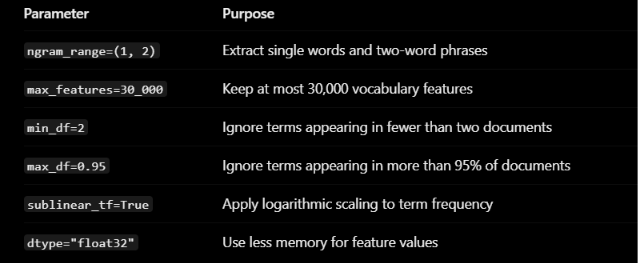

In [12]:
X_tfidf = vectorizer.fit_transform(
    df["cleaned_text"].fillna("")
)

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Number of vocabulary features:", len(vectorizer.vocabulary_))
print("Matrix data type:", X_tfidf.dtype)
print("Non-zero values:", X_tfidf.nnz)

TF-IDF matrix shape: (20000, 30000)
Number of vocabulary features: 30000
Matrix data type: float32
Non-zero values: 1753620


In [13]:
vocabulary = vectorizer.get_feature_names_out()

print("First 50 features:")
print(vocabulary[:50])

First 50 features:
['00' '00 for' '000' '01' '02' '03' '05' '06' '07' '10' '10 00' '10 10'
 '10 15' '10 and' '10 bucks' '10 days' '10 for' '10 hours' '10 minutes'
 '10 months' '10 pages' '10 seconds' '10 the' '10 times' '10 year'
 '10 years' '100' '100 pages' '1000' '101' '10th' '11' '11 and' '11 year'
 '110' '12' '12 hours' '12 year' '12 years' '120' '125' '13' '14'
 '14 years' '15' '15 20' '15 minutes' '15 year' '15 years' '150']


In [14]:
feature_names = vectorizer.get_feature_names_out()

review_index = 0
row = X_tfidf[review_index]

feature_values = pd.DataFrame({
    "feature": feature_names[row.indices],
    "tfidf_score": row.data
}).sort_values(
    "tfidf_score",
    ascending=False
)

print("Review:")
print(df.loc[review_index, "cleaned_text"])

feature_values.head(15)

Review:
good diapers some blowouts i like these diapers and it's great to get so many at once but we have had some blowouts up the back


,feature,tfidf_score
1,diapers,0.349144
23,diapers and,0.272573
28,get so,0.267895
30,at once,0.247492
22,these diapers,0.246345
21,like these,0.237510
31,but we,0.227892
26,great to,0.224835
34,had some,0.224256
25,it great,0.194190


In [15]:
import numpy as np

sparse_memory_mb = (
    X_tfidf.data.nbytes
    + X_tfidf.indices.nbytes
    + X_tfidf.indptr.nbytes
) / (1024 ** 2)

dense_memory_mb = (
    X_tfidf.shape[0]
    * X_tfidf.shape[1]
    * np.dtype("float32").itemsize
) / (1024 ** 2)

print(f"Sparse matrix memory: {sparse_memory_mb:.2f} MB")
print(f"Dense matrix equivalent: {dense_memory_mb:.2f} MB")

Sparse matrix memory: 13.46 MB
Dense matrix equivalent: 2288.82 MB
